# FINAL: Earth analogs for Mars (reference site: Viking 2, Utopia Planitia)
Earth data: NASA MERRA-2 (Earthdata). Mars reference values: Viking 2 data from the PDS Atmospheres Node.
Run the cells in order. Edit only section 2.

In [1]:
!pip install -q earthaccess xarray netCDF4 pandas matplotlib folium

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.


## 1) Login to Earthdata (also approve the GES DISC application in your Earthdata profile)

In [2]:
import os, getpass, earthaccess
os.environ["EARTHDATA_TOKEN"] = getpass.getpass("Paste your Earthdata token: ")
auth = earthaccess.login(strategy="environment")
print("logged in:", auth.authenticated)

Paste your Earthdata token: ··········
logged in: True


## 2) Settings (EDIT HERE)
- `SITES`: the team's Earth sites (lat, lon). Placeholders below, replace them.
- `MARS`: paste the dictionary printed by the Viking extraction cell.

In [3]:
YEAR = 2022

SITES = {
    "McMurdo Dry Valleys (Antarctica)": (-77.5, 162.0),
    "Gilf Kebir (Egypt)":               (23.3, 26.1),
    "Altiplano (Bolivia)":              (-19.5, -67.8),
    "Atacama-Puna (Chile/Argentina)":   (-24.5, -67.5),
    "Tuktoyaktuk (Canadian Arctic)":    (69.4, -133.0),
    "Askja-Odadahraun (Iceland)":       (65.0, -17.0),
    "Meteor Crater (Arizona)":          (35.0, -111.0),
    "Teide (Tenerife, Spain)":          (28.3, -16.6),
}

MARS = {
    "ts_mean_K": 193.7,
    "elevation_m": -4000,
    "dust_aod": 0.85,
    "lai": 0.0,
    "soil_wetness": 0.0,
    "wind_ms": 4.48,
    "pressure_Pa": 874,
}

SCALE   = {"ts_mean_K": 100, "elevation_m": 5000, "dust_aod": 0.5, "lai": 1.0, "soil_wetness": 1.0, "wind_ms": 5.0}
WEIGHTS = {"ts_mean_K": 1, "elevation_m": 0, "dust_aod": 1, "lai": 1, "soil_wetness": 1, "wind_ms": 1}

## 3) Download MERRA-2 (monthly files)

In [4]:
import xarray as xr

def get_files(short_name, **kw):
    res = earthaccess.search_data(short_name=short_name, **kw)
    print(short_name, "->", len(res), "granules")
    return earthaccess.download(res, "data")

period = dict(temporal=(f"{YEAR}-01-01", f"{YEAR}-12-31"))
slv  = xr.open_mfdataset(get_files("M2TMNXSLV", **period), combine="by_coords")
aer  = xr.open_mfdataset(get_files("M2TMNXAER", **period), combine="by_coords")
lnd  = xr.open_mfdataset(get_files("M2TMNXLND", **period), combine="by_coords")
cnst = xr.open_dataset(get_files("M2C0NXASM")[0])

# Viking measured AIR temperature and wind at ~1.6 m, so use 2 m variables when they exist
TVAR = "T2M" if "T2M" in slv.data_vars else "TS"
UVAR, VVAR = ("U2M", "V2M") if "U2M" in slv.data_vars and "V2M" in slv.data_vars else ("U10M", "V10M")
print("temperature variable:", TVAR, "| wind variables:", UVAR, VVAR)
for name, ds, names in [("slv", slv, [TVAR, UVAR, VVAR, "PS"]), ("aer", aer, ["DUEXTTAU"]),
                        ("lnd", lnd, ["LAI", "GWETTOP"]), ("cnst", cnst, ["PHIS"])]:
    miss = [v for v in names if v not in ds.data_vars]
    print(name, "OK" if not miss else f"MISSING {miss} | available: {list(ds.data_vars)}")

M2TMNXSLV -> 12 granules


QUEUEING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/12 [00:00<?, ?it/s]

M2TMNXAER -> 12 granules


QUEUEING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

... (7 outputs left out)

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

temperature variable: T2M | wind variables: U2M V2M
slv OK
aer OK
lnd OK
cnst OK


## 4) Values for each site

In [5]:
import numpy as np
import pandas as pd

def at(ds, var, lat, lon):
    return ds[var].sel(lat=lat, lon=lon, method="nearest")

rows = []
for name, (lat, lon) in SITES.items():
    t   = at(slv, TVAR, lat, lon).values
    u   = at(slv, UVAR, lat, lon).values
    v   = at(slv, VVAR, lat, lon).values
    ps  = at(slv, "PS", lat, lon).values
    d   = at(aer, "DUEXTTAU", lat, lon).values
    lai = at(lnd, "LAI", lat, lon).values
    wet = at(lnd, "GWETTOP", lat, lon).values
    phi = at(cnst, "PHIS", lat, lon).values.squeeze()
    rows.append({"site": name, "lat": lat, "lon": lon,
        "ts_mean_K": float(np.nanmean(t)), "ts_seasonal_range_K": float(np.nanmax(t) - np.nanmin(t)),
        "elevation_m": float(phi) / 9.80665, "dust_aod": float(np.nanmean(d)),
        "lai": float(np.nanmean(lai)), "soil_wetness": float(np.nanmean(wet)),
        "wind_ms": float(np.nanmean(np.sqrt(u**2 + v**2))), "pressure_Pa": float(np.nanmean(ps))})
df = pd.DataFrame(rows)
df["pressure_ratio_to_Mars"] = df["pressure_Pa"] / MARS["pressure_Pa"]
df.round(3)

/tmp/ipykernel_295/709118326.py:20: RuntimeWarning: Mean of empty slice
  "lai": float(np.nanmean(lai)), "soil_wetness": float(np.nanmean(wet)),


,site,lat,lon,ts_mean_K,ts_seasonal_range_K,elevation_m,dust_aod,lai,soil_wetness,wind_ms,pressure_Pa,pressure_ratio_to_Mars
0,McMurdo Dry Valleys (Antarctica),-77.5,162.0,246.880,19.885,1139.189,0.003,NaN,1.000,5.353,84859.930,97.094
1,Gilf Kebir (Egypt),23.3,26.1,292.543,20.605,890.119,0.130,0.228,0.080,2.556,91549.852,104.748
2,Altiplano (Bolivia),-19.5,-67.8,281.545,8.778,3752.961,0.004,0.316,0.307,1.112,64936.559,74.298
3,Atacama-Puna (Chile/Argentina),-24.5,-67.5,279.213,11.272,3727.116,0.005,0.244,0.336,2.456,65092.277,74.476
4,Tuktoyaktuk (Canadian Arctic),69.4,-133.0,264.411,37.270,12.975,0.016,0.567,0.752,0.902,101546.539,116.186
5,Askja-Odadahraun (Iceland),65.0,-17.0,270.178,14.593,801.833,0.011,0.229,0.861,2.042,91088.023,104.220
6,Meteor Crater (Arizona),35.0,-111.0,284.666,23.203,1915.575,0.019,1.421,0.408,1.032,80976.711,92.651
7,"Teide (Tenerife, Spain)",28.3,-16.6,293.790,5.795,138.224,0.111,0.000,0.582,3.924,100222.000,114.670


## 5) Similarity scores (missing variables are ignored, not counted as zero)

In [6]:
for k in SCALE:
    df["score_" + k] = (100 * (1 - (df[k] - MARS[k]).abs() / SCALE[k])).clip(lower=0)

def total_score(frame, weights):
    cols = ["score_" + k for k in SCALE]
    W = pd.Series({"score_" + k: weights[k] for k in SCALE}, dtype=float)
    ok = frame[cols].notna()
    return (frame[cols].fillna(0) * W).sum(axis=1) / (ok * W).sum(axis=1)

df["score_total"] = total_score(df, WEIGHTS)
df = df.sort_values("score_total", ascending=False).reset_index(drop=True)
df.round(1)

,site,lat,lon,ts_mean_K,ts_seasonal_range_K,elevation_m,dust_aod,lai,soil_wetness,wind_ms,pressure_Pa,pressure_ratio_to_Mars,score_ts_mean_K,score_elevation_m,score_dust_aod,score_lai,score_soil_wetness,score_wind_ms,score_total
0,Gilf Kebir (Egypt),23.3,26.1,292.5,20.6,890.1,0.1,0.2,0.1,2.6,91549.9,104.7,1.2,2.2,0.0,77.2,92.0,61.5,46.4
1,"Teide (Tenerife, Spain)",28.3,-16.6,293.8,5.8,138.2,0.1,0.0,0.6,3.9,100222.0,114.7,0.0,17.2,0.0,100.0,41.8,88.9,46.1
2,Atacama-Puna (Chile/Argentina),-24.5,-67.5,279.2,11.3,3727.1,0.0,0.2,0.3,2.5,65092.3,74.5,14.5,0.0,0.0,75.6,66.4,59.5,43.2
3,Altiplano (Bolivia),-19.5,-67.8,281.5,8.8,3753.0,0.0,0.3,0.3,1.1,64936.6,74.3,12.2,0.0,0.0,68.4,69.3,32.6,36.5
4,Askja-Odadahraun (Iceland),65.0,-17.0,270.2,14.6,801.8,0.0,0.2,0.9,2.0,91088.0,104.2,23.5,4.0,0.0,77.1,13.9,51.2,33.1
5,McMurdo Dry Valleys (Antarctica),-77.5,162.0,246.9,19.9,1139.2,0.0,NaN,1.0,5.4,84859.9,97.1,46.8,0.0,0.0,NaN,0.0,82.5,32.3
6,Tuktoyaktuk (Canadian Arctic),69.4,-133.0,264.4,37.3,13.0,0.0,0.6,0.8,0.9,101546.5,116.2,29.3,19.7,0.0,43.3,24.8,28.4,25.2
7,Meteor Crater (Arizona),35.0,-111.0,284.7,23.2,1915.6,0.0,1.4,0.4,1.0,80976.7,92.7,9.0,0.0,0.0,0.0,59.2,31.0,19.8


## 6) Pressure: where the analogy fails

In [7]:
df[["site", "pressure_Pa", "pressure_ratio_to_Mars"]].round(1)

,site,pressure_Pa,pressure_ratio_to_Mars
0,Gilf Kebir (Egypt),91549.9,104.7
1,"Teide (Tenerife, Spain)",100222.0,114.7
2,Atacama-Puna (Chile/Argentina),65092.3,74.5
3,Altiplano (Bolivia),64936.6,74.3
4,Askja-Odadahraun (Iceland),91088.0,104.2
5,McMurdo Dry Valleys (Antarctica),84859.9,97.1
6,Tuktoyaktuk (Canadian Arctic),101546.5,116.2
7,Meteor Crater (Arizona),80976.7,92.7


## 7) Chart

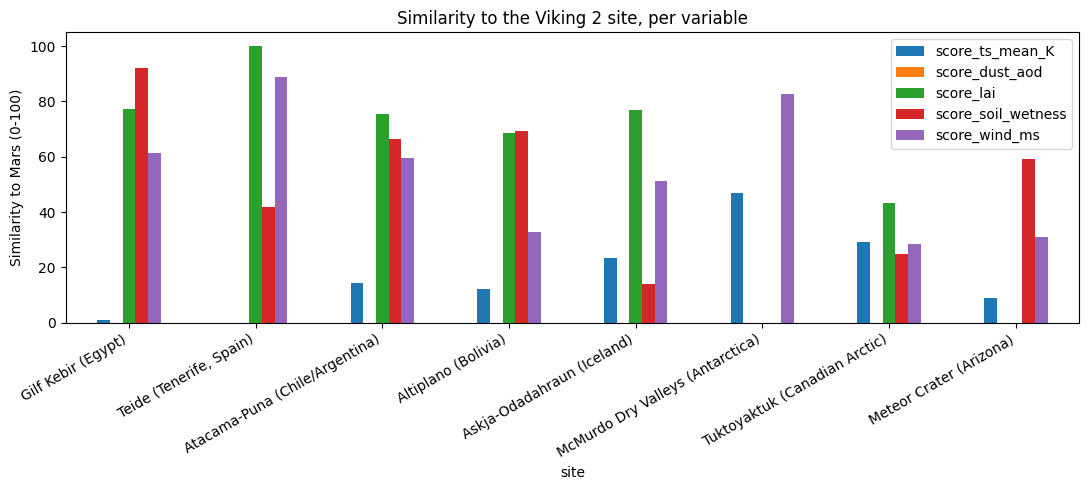

In [8]:
import matplotlib.pyplot as plt
cols = ["score_" + k for k in SCALE if WEIGHTS[k] > 0]
ax = df.set_index("site")[cols].plot(kind="bar", figsize=(11, 5))
ax.set_ylabel("Similarity to Mars (0-100)"); ax.set_title("Similarity to the Viking 2 site, per variable")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.savefig("scores.png", dpi=150); plt.show()

## 8) Sensitivity analysis (does the ranking change with the weights?)

In [9]:
scen = {
    "equal":          {"ts_mean_K": 1, "elevation_m": 0, "dust_aod": 1, "lai": 1, "soil_wetness": 1, "wind_ms": 1},
    "temperature x3": {"ts_mean_K": 3, "elevation_m": 0, "dust_aod": 1, "lai": 1, "soil_wetness": 1, "wind_ms": 1},
    "dust+wind x3":   {"ts_mean_K": 1, "elevation_m": 0, "dust_aod": 3, "lai": 1, "soil_wetness": 1, "wind_ms": 3},
    "with elevation": {"ts_mean_K": 1, "elevation_m": 1, "dust_aod": 1, "lai": 1, "soil_wetness": 1, "wind_ms": 1},
}
sens = pd.DataFrame({"site": df["site"]})
for label, w in scen.items():
    sens[label] = total_score(df, w)
    sens[label + " (rank)"] = sens[label].rank(ascending=False).astype(int)
sens.round(1)

,site,equal,equal (rank),temperature x3,temperature x3 (rank),dust+wind x3,dust+wind x3 (rank),with elevation,with elevation (rank)
0,Gilf Kebir (Egypt),46.4,1,33.5,3,39.4,2,39.0,2
1,"Teide (Tenerife, Spain)",46.1,2,33.0,4,45.4,1,41.3,1
2,Atacama-Puna (Chile/Argentina),43.2,3,35.0,2,37.2,3,36.0,3
3,Altiplano (Bolivia),36.5,4,29.5,6,27.5,6,30.4,4
4,Askja-Odadahraun (Iceland),33.1,5,30.4,5,29.8,5,28.3,5
5,McMurdo Dry Valleys (Antarctica),32.3,6,37.2,1,36.8,4,25.9,6
6,Tuktoyaktuk (Canadian Arctic),25.2,7,26.3,7,20.3,7,24.3,7
7,Meteor Crater (Arizona),19.8,8,16.8,8,17.9,8,16.5,8


## 9) Map

In [10]:
import folium
m = folium.Map(location=[20, 30], zoom_start=2, tiles="CartoDB positron")
for _, r in df.iterrows():
    tip = (f"<b>{r['site']}</b><br>Total: {r['score_total']:.0f}<br>Temp {r['score_ts_mean_K']:.0f} | Dust {r['score_dust_aod']:.0f}"
           f"<br>Vegetation {r['score_lai']:.0f} | Soil moisture {r['score_soil_wetness']:.0f} | Wind {r['score_wind_ms']:.0f}"
           f"<br>Pressure: {r['pressure_ratio_to_Mars']:.0f}x Mars")
    color = "green" if r["score_total"] >= 70 else "orange" if r["score_total"] >= 40 else "red"
    folium.Marker([r["lat"], r["lon"]], popup=folium.Popup(tip, max_width=260), icon=folium.Icon(color=color)).add_to(m)
m.save("map.html")
m

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


## 10) Save everything (download, then upload to GitHub)

In [11]:
df.to_csv("results.csv", index=False); sens.to_csv("sensitivity.csv", index=False)
pd.Series(MARS).to_csv("mars_reference_values.csv", header=["value"])
from google.colab import files
for f in ["results.csv", "sensitivity.csv", "mars_reference_values.csv", "map.html", "scores.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
df.to_csv("results.csv", index=False)
sens.to_csv("sensitivity.csv", index=False)